In [ ]:
# Colab: mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

!pip -q install openpyxl  # for reading .xlsx if needed


Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import os

# ==== EDIT THIS PATH ====
file_path = "/content/drive/MyDrive/returns_2022_filled.csv"  # or .xlsx

# If the first column is a Date, set this True to use it as the index
use_first_col_as_index = True

def load_returns(path: str, use_index=True) -> pd.DataFrame:
    ext = os.path.splitext(path)[1].lower()
    if ext == ".csv":
        df = pd.read_csv(path)
    elif ext in [".xlsx", ".xls"]:
        df = pd.read_excel(path)
    else:
        raise ValueError("Unsupported file type. Use .csv or .xlsx")

    if use_index and df.shape[1] > 1:
        df = df.set_index(df.columns[0])

    # Keep only numeric columns (drop any stray text columns)
    df = df.select_dtypes(include=[np.number])

    # Auto-fix % inputs → decimals if typical magnitudes > 1
    q90 = df.abs().quantile(0.90).median()
    if q90 > 1.0:
        df = df / 100.0

    # Drop constant/near-constant columns that break corr/cov
    variances = df.var(skipna=True)
    low_var_cols = variances[variances <= 1e-12].index.tolist()
    if low_var_cols:
        df = df.drop(columns=low_var_cols, errors='ignore')

    return df

returns_raw = load_returns(file_path, use_index=use_first_col_as_index)
print("Loaded shape:", returns_raw.shape)
returns_raw.head()


Loaded shape: (869, 102)


,BHARTIARTL,LUPIN,TECHNOE,CGPOWER,TITAN,GODREJCP,HDFCLIFE,ICICIBANK,HAL,VOLTAMP,...,MOTHERSON,GALAXYSURF,DIVISLAB,ARVINDFASN,SBIN,BAJFINANCE,SANSERA,M&M,PERSISTENT,BLUESTARCO
Date,,,,,,,,,,,,,,,,,,,,,
2022-01-03,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2022-01-04,0.008896,-0.013647,0.025368,0.043345,0.023436,-0.008250,0.004074,0.010658,0.012078,0.008317,...,-0.000222,-0.001926,-0.006353,0.031726,0.026975,0.017092,-0.003859,0.002470,-0.007369,0.012016
2022-01-05,0.003656,-0.000322,-0.014765,-0.009042,-0.002652,0.005107,0.000612,0.019668,0.016899,0.002741,...,-0.003114,0.002057,-0.013685,-0.021507,0.018407,0.044641,0.000581,0.009196,-0.032515,-0.028418
2022-01-06,0.014857,-0.009549,0.010936,-0.023921,0.007666,-0.005762,-0.010175,-0.003807,-0.016815,-0.008645,...,0.039045,-0.003850,-0.015203,0.006903,-0.001422,0.010097,-0.012839,0.000417,-0.030947,0.018532
2022-01-07,-0.008024,-0.007691,-0.014022,0.007327,-0.008937,0.008956,0.020714,0.010445,0.006609,0.020869,...,0.025982,-0.001741,0.006137,-0.008840,-0.000915,-0.011474,0.018562,-0.012919,0.002415,-0.017162


In [ ]:
def prepare_trading_panel(df: pd.DataFrame):
    # zero-only row = all NaN treated as 0, then abs sum == 0 (tolerance optional)
    zero_like = (df.fillna(0).abs().sum(axis=1) <= 1e-12)
    df_trading = df.loc[~zero_like].copy()

    # Try to infer years from datetime index span
    AF = 252.0  # default fallback
    years = None
    try:
        idx = pd.to_datetime(df_trading.index)
        span_days = (idx.max() - idx.min()).days
        years = span_days / 365.25 if span_days > 0 else None
        if years and years > 0:
            AF = len(df_trading) / years
    except Exception:
        pass

    print(f"Total rows: {len(df)} | Trading rows kept: {len(df_trading)} | Dropped: {len(df) - len(df_trading)}")
    print(f"Inferred AF (obs/year): {AF:.2f}" + ("" if years else " (no dates parsed; used default 252)"))
    return df_trading, AF

returns, AF = prepare_trading_panel(returns_raw)


Total rows: 869 | Trading rows kept: 867 | Dropped: 2
Inferred AF (obs/year): 247.01


In [ ]:
# Mean (arithmetic) daily expected return per ticker
er_daily = returns.mean(skipna=True)

# Geometric approach via log(1+r)
log1p = np.log1p(returns)
mu_log_daily = log1p.mean(skipna=True)

# Annualized expected returns
expected_annual_arith = er_daily * AF
expected_annual_geo   = np.expm1(mu_log_daily * AF)

expected_df = pd.DataFrame({
    "expected_daily_mean": er_daily,
    "expected_annual_arith": expected_annual_arith,
    "expected_annual_geo": expected_annual_geo
}).sort_index()

# Save the table next to your source file
out_dir = os.path.dirname(file_path) or "/content"
expected_path = os.path.join(out_dir, "expected_returns.csv")
expected_df.to_csv(expected_path)
print(f"Saved expected returns → {expected_path}")
expected_df.head()


Saved expected returns → /content/drive/MyDrive/expected_returns.csv


,expected_daily_mean,expected_annual_arith,expected_annual_geo
ANANTRAJ,0.002820,0.696685,0.757972
APARINDS,0.003334,0.823566,1.010670
ARVINDFASN,0.000916,0.226259,0.164449
BAJAJ-AUTO,0.001318,0.325541,0.342645
BAJFINANCE,0.000456,0.112523,0.077917


In [ ]:
FILTER_METRIC = "geo_annual"  # options: "geo_annual", "arith_annual", "daily"

if FILTER_METRIC == "geo_annual":
    positive_tickers = expected_df.index[expected_df["expected_annual_geo"] > 0].tolist()
elif FILTER_METRIC == "arith_annual":
    positive_tickers = expected_df.index[expected_df["expected_annual_arith"] > 0].tolist()
elif FILTER_METRIC == "daily":
    positive_tickers = expected_df.index[expected_df["expected_daily_mean"] > 0].tolist()
else:
    raise ValueError("FILTER_METRIC must be one of: 'geo_annual', 'arith_annual', 'daily'")

returns_pos = returns.loc[:, positive_tickers]
print(f"Positive-ER tickers ({FILTER_METRIC}): {len(positive_tickers)}")

filtered_returns_path = os.path.join(out_dir, "returns_positive.csv")
returns_pos.to_csv(filtered_returns_path)
print(f"Saved filtered daily return series → {filtered_returns_path}")


Positive-ER tickers (geo_annual): 91
Saved filtered daily return series → /content/drive/MyDrive/returns_positive.csv


In [ ]:
if returns_pos.shape[1] == 0:
    raise RuntimeError("No stocks with positive expected return after filtering. Change FILTER_METRIC or inspect data.")

# Daily covariance & correlation on trading-only rows
cov_daily = returns_pos.cov()
corr = returns_pos.corr()

# Annualize covariance with AF
cov_annual = cov_daily * AF

# Save
cov_daily_path = os.path.join(out_dir, "covariance_daily.csv")
cov_annual_path = os.path.join(out_dir, "covariance_annual.csv")
corr_path = os.path.join(out_dir, "correlation.csv")

cov_daily.to_csv(cov_daily_path)
cov_annual.to_csv(cov_annual_path)
corr.to_csv(corr_path)

print(f"Saved covariance (daily)     → {cov_daily_path}")
print(f"Saved covariance (annualized)→ {cov_annual_path}")
print(f"Saved correlation matrix     → {corr_path}")


Saved covariance (daily)     → /content/drive/MyDrive/covariance_daily.csv
Saved covariance (annualized)→ /content/drive/MyDrive/covariance_annual.csv
Saved correlation matrix     → /content/drive/MyDrive/correlation.csv


In [1]:
# ===== Step 6 — Select 12 least-correlated tickers and save results =====
import numpy as np
import pandas as pd
import os

# Safety checks for prerequisites from earlier steps
if 'returns_pos' not in globals():
    raise RuntimeError("`returns_pos` is not defined. Run Steps 1–4 first to create the filtered returns panel.")
out_dir = (out_dir if 'out_dir' in globals() else "/content")

def select_low_corr_assets(corr_matrix: pd.DataFrame, k=12, use_abs=True):
    """
    Greedy farthest-first selection to minimize average (absolute) correlation among chosen assets.
    - corr_matrix: pandas correlation matrix (tickers x tickers)
    - k: number of assets to select
    - use_abs: if True, penalize both positive and negative high correlations (use |corr|)
    """
    if corr_matrix.shape[0] == 0:
        return []

    C = corr_matrix.copy().fillna(0.0)
    if use_abs:
        C = C.abs()

    # Ensure diagonal = 1 to avoid weirdness
    np.fill_diagonal(C.values, 1.0)

    tickers = C.index.tolist()
    n = len(tickers)
    if n <= k:
        return tickers

    # Seed = ticker with smallest avg |corr| to all others (exclude self-corr)
    avg_corr = (C.sum(axis=1) - 1.0) / (n - 1)
    seed = avg_corr.idxmin()

    selected = [seed]
    remaining = [t for t in tickers if t != seed]

    while len(selected) < k and remaining:
        best_ticker, best_score = None, float("inf")
        for t in remaining:
            score = C.loc[t, selected].mean()
            if score < best_score:
                best_score, best_ticker = score, t
        selected.append(best_ticker)
        remaining.remove(best_ticker)

    return selected

# Compute correlation from the filtered panel (recompute here to be self-contained)
corr = returns_pos.corr()

USE_ABS = True  # True = avoid both highly +ve and highly -ve correlations
K = 12

if returns_pos.shape[1] == 0:
    raise RuntimeError("No stocks with positive expected return after filtering. Change FILTER_METRIC or inspect data.")

chosen = select_low_corr_assets(corr, k=min(K, returns_pos.shape[1]), use_abs=USE_ABS)
print(f"Selected {len(chosen)} low-correlation tickers:")
println(chosen)

# Save chosen tickers
sel_path = os.path.join(out_dir, "selected_12_stocks.csv")
pd.Series(chosen, name="ticker").to_csv(sel_path, index=False)
print(f"Saved chosen tickers → {sel_path}")

# Save their daily return series
portfolio_returns = returns_pos[chosen]
portfolio_returns_path = os.path.join(out_dir, "portfolio_12_returns.csv")
portfolio_returns.to_csv(portfolio_returns_path)
print(f"Saved chosen portfolio returns → {portfolio_returns_path}")

# (Optional) quick sanity checks
print("Panel shape (rows x cols) of selected portfolio:", portfolio_returns.shape)


RuntimeError: `returns_pos` is not defined. Run Steps 1–4 first to create the filtered returns panel.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 222.1/222.1 kB 845.1 kB/s eta 0:00:00
Trading rows kept: 866 | Inferred AF (obs/year): 246.92
Tickers (12): ['JYOTHYLAB', 'CIPLA', 'CRAFTSMAN', 'SAPPHIRE', 'MAXHEALTH', 'KPRMILL', 'POWERINDIA', 'APARINDS', 'PHOENIXLTD', 'VIJAYA', 'ITC', 'SUVENPHAR']
Highest annual expected return: APARINDS 82.4209%
Lowest  annual expected return: SAPPHIRE 15.2872%
Saved efficient frontier with TC → /content/drive/MyDrive/efficient_frontier_weights_with_TC.csv
Frontier points: 60


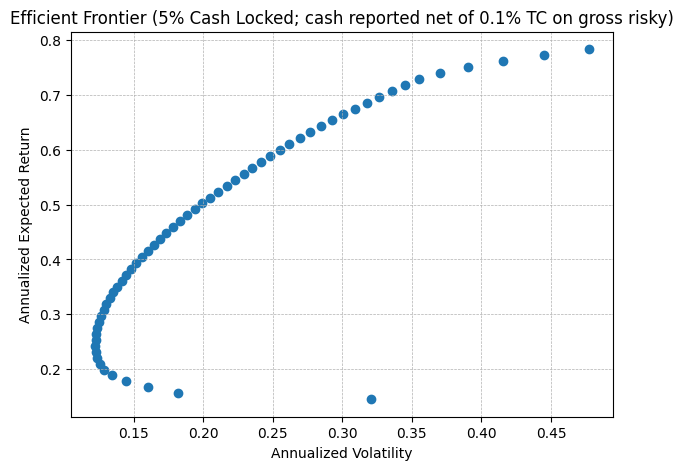


Min-Vol frontier point:
Return: 24.2516% | Vol: 12.2561%
Cash (gross): 5.00% | Cash (net after TC): 4.91% | TC (₹): 9,500

Weights at min-vol point (including risky assets; cash shown separately above):
w_ITC           0.301851
w_CIPLA         0.204386
w_SAPPHIRE      0.077048
w_JYOTHYLAB     0.070624
w_KPRMILL       0.061935
w_SUVENPHAR      0.05685
w_CRAFTSMAN     0.050115
w_MAXHEALTH     0.047347
w_PHOENIXLTD    0.041819
w_VIJAYA        0.017213
w_POWERINDIA    0.011769
w_APARINDS      0.009043


In [ ]:
# ======================= Efficient Frontier + 0.1% TC on gross risky exposure =======================
# Installs
!pip -q install cvxpy ecos osqp openpyxl

import os, math, numpy as np, pandas as pd, cvxpy as cp
import matplotlib.pyplot as plt

# ---------- CONFIG ----------
out_dir      = "/content/drive/MyDrive"
p12_path     = os.path.join(out_dir, "portfolio_12_returns.csv")

CASH_W       = 0.05     # fixed 5% cash (gross, BEFORE transaction costs)
RISK_FREE    = 0.00     # annual cash/risk-free rate
GRID_N       = 60       # number of frontier points to compute
CAPITAL_RS   = 1e7      # ₹1 crore

# Shorting controls
ALLOW_SHORTS     = False        # True to allow shorts inside the risky sleeve
L1_GROSS_LIMIT   = None         # e.g., 1.5 to cap |x|_1 for leverage control (used only if ALLOW_SHORTS=True)

# ---------- HELPERS ----------
def load_portfolio_returns(path):
    if not os.path.exists(path):
        raise FileNotFoundError(f"Could not find {path}.")
    df = pd.read_csv(path)
    if df.shape[1] > 1:
        df = df.set_index(df.columns[0])
    return df.select_dtypes(include=[np.number])

def infer_panel_and_AF(df: pd.DataFrame):
    """Drop zero-only rows and infer annualization factor from date span."""
    zero_like = (df.fillna(0).abs().sum(axis=1) <= 1e-12)
    df = df.loc[~zero_like].copy()
    AF = 252.0
    try:
        idx = pd.to_datetime(df.index)
        span_days = (idx.max() - idx.min()).days
        years = span_days / 365.25 if span_days > 0 else None
        if years and years > 0:
            AF = len(df) / years
    except Exception:
        pass
    print(f"Trading rows kept: {len(df)} | Inferred AF (obs/year): {AF:.2f}")
    return df, AF

def nearest_psd(S, eps=1e-10):
    """Project a symmetric matrix to the nearest PSD (clip negative eigenvalues)."""
    S = (S + S.T) / 2.0
    vals, vecs = np.linalg.eigh(S)
    vals = np.clip(vals, eps, None)
    return vecs @ np.diag(vals) @ vecs.T

# ---------- LOAD & PREP ----------
returns_df = load_portfolio_returns(p12_path)
returns_df, AF = infer_panel_and_AF(returns_df)

tickers = list(returns_df.columns)
n = len(tickers)
if n == 0:
    raise RuntimeError("No columns found in returns panel.")
print(f"Tickers ({n}): {tickers}")

# ---------- EXPECTED RETURNS & COVARIANCE (annualized) ----------
mu_daily = returns_df.mean(skipna=True)         # arithmetic daily mean
mu_ann   = mu_daily * AF                        # annualized ER (arithmetic)
Sigma_d  = returns_df.cov()                     # daily covariance
Sigma_a  = nearest_psd(Sigma_d.values * AF)     # annualized covariance (PSD)

# Highest / Lowest ER stocks
max_t = mu_ann.idxmax()
min_t = mu_ann.idxmin()
print("Highest annual expected return:", max_t, f"{mu_ann[max_t]:.4%}")
print("Lowest  annual expected return:",  min_t, f"{mu_ann[min_t]:.4%}")

# ---------- EFFICIENT FRONTIER WITH 5% CASH LOCKED ----------
# Decision var x: risky weights *within the risky sleeve* that sum to 1
x = cp.Variable(n)
mu_vec = mu_ann.values
Sigma_risky = Sigma_a

# Target total portfolio return grid
Rp_min = (1 - CASH_W) * mu_ann.min() + CASH_W * RISK_FREE
Rp_max = (1 - CASH_W) * mu_ann.max() + CASH_W * RISK_FREE
Rp_grid = np.linspace(Rp_min, Rp_max, GRID_N)

frontier_records = []
for Rp in Rp_grid:
    # Implied target return for the risky sleeve
    target_risky_ret = (Rp - CASH_W * RISK_FREE) / (1 - CASH_W)

    constraints = [cp.sum(x) == 1.0, mu_vec @ x == target_risky_ret]
    if not ALLOW_SHORTS:
        constraints.append(x >= 0)
    if ALLOW_SHORTS and (L1_GROSS_LIMIT is not None):
        constraints.append(cp.norm1(x) <= L1_GROSS_LIMIT)

    objective = cp.Minimize(cp.quad_form(x, Sigma_risky))
    prob = cp.Problem(objective, constraints)

    solved = False
    for solver in [cp.ECOS, cp.OSQP, cp.SCS]:
        try:
            prob.solve(solver=solver, verbose=False)
            if x.value is not None and prob.status in ("optimal", "optimal_inaccurate"):
                solved = True
                break
        except Exception:
            continue
    if not solved:
        continue

    x_opt = np.array(x.value, dtype=float)
    if not ALLOW_SHORTS:
        x_opt = np.maximum(x_opt, 0)
    s = x_opt.sum()
    if s <= 0:
        continue
    x_opt = x_opt / s

    # Total portfolio risky weights (scaled by 0.95)
    w_risky = (1 - CASH_W) * x_opt

    # Portfolio stats (before TC)
    port_ret = (1 - CASH_W) * (mu_vec @ x_opt) + CASH_W * RISK_FREE
    port_var = (1 - CASH_W)**2 * (x_opt @ Sigma_risky @ x_opt)
    port_vol = math.sqrt(max(port_var, 0))

    # ---------- Transaction cost on gross invested (long + short) ----------
    gross_risky_weight = float(np.sum(np.abs(w_risky)))  # total |weights| in risky assets
    TC_weight          = 0.001 * gross_risky_weight      # 0.1% of gross risky weight
    TC_rupees          = TC_weight * CAPITAL_RS

    # Cash before & after TC (reporting)
    cash_weight_gross  = CASH_W
    cash_weight_net    = CASH_W - TC_weight
    cash_rupees_gross  = cash_weight_gross * CAPITAL_RS
    cash_rupees_net    = cash_weight_net  * CAPITAL_RS

    rec = {
        "target_return": port_ret,
        "volatility": port_vol,
        "cash_weight_gross": cash_weight_gross,
        "cash_weight_net_after_TC": cash_weight_net,
        "cash_rupees_gross": cash_rupees_gross,
        "cash_rupees_net_after_TC": cash_rupees_net,
        "transaction_cost_weight": TC_weight,
        "transaction_cost_rupees": TC_rupees,
        "gross_risky_weight": gross_risky_weight,
        "risk_free": RISK_FREE,
        "allow_shorts": ALLOW_SHORTS
    }
    # Per-asset total portfolio weights (already include the 0.95 scaling)
    for t, w in zip(tickers, w_risky):
        rec[f"w_{t}"] = w
    # Also store the reported cash (net) as a weight
    rec["w_CASH_reported_net"] = cash_weight_net

    frontier_records.append(rec)

if not frontier_records:
    raise RuntimeError("No efficient frontier points were found. Check data/constraints.")

frontier_df = pd.DataFrame(frontier_records).sort_values("volatility").reset_index(drop=True)

# ---------- SAVE WEIGHTS GRID ----------
ef_path = os.path.join(out_dir, "efficient_frontier_weights_with_TC.csv")
frontier_df.to_csv(ef_path, index=False)
print(f"Saved efficient frontier with TC → {ef_path}")
print(f"Frontier points: {len(frontier_df)}")

# ---------- PLOT FRONTIER ----------
plt.figure(figsize=(7,5))
plt.scatter(frontier_df["volatility"], frontier_df["target_return"])
plt.xlabel("Annualized Volatility")
plt.ylabel("Annualized Expected Return")
plt.title("Efficient Frontier (5% Cash Locked; cash reported net of 0.1% TC on gross risky)")
plt.grid(True, linestyle="--", linewidth=0.5)
plt.show()

# ---------- Show min-vol point summary ----------
minvol_idx = frontier_df["volatility"].idxmin()
print("\nMin-Vol frontier point:")
print("Return:", f"{frontier_df.loc[minvol_idx, 'target_return']:.4%}",
      "| Vol:", f"{frontier_df.loc[minvol_idx, 'volatility']:.4%}")
print("Cash (gross):", f"{frontier_df.loc[minvol_idx, 'cash_weight_gross']:.2%}",
      "| Cash (net after TC):", f"{frontier_df.loc[minvol_idx, 'cash_weight_net_after_TC']:.2%}",
      "| TC (₹):", f"{frontier_df.loc[minvol_idx, 'transaction_cost_rupees']:,.0f}")

# Sort and display weights (descending) for the min-vol point
weight_cols = [c for c in frontier_df.columns if c.startswith("w_") and c != "w_CASH_reported_net"]
minvol_weights = frontier_df.loc[minvol_idx, weight_cols].sort_values(ascending=False)
print("\nWeights at min-vol point (including risky assets; cash shown separately above):")
print(minvol_weights.to_string())
# ========================================================================================================


In [ ]:
# ===================== Min-Variance & Target-Vol (1%) Portfolio with 5% Cash & 0.1% TC =====================
# Installs
!pip -q install cvxpy ecos osqp openpyxl

import os, math, numpy as np, pandas as pd, cvxpy as cp
import matplotlib.pyplot as plt

# ---------- CONFIG ----------
out_dir       = "/content/drive/MyDrive"
p12_path      = os.path.join(out_dir, "portfolio_12_returns.csv")

CASH_W        = 0.05       # fixed 5% cash (gross, BEFORE transaction costs)
RISK_FREE     = 0.00       # annual cash yield
CAPITAL_RS    = 1e7        # ₹1 crore
SIGMA_TARGET  = 0.01       # <-- 1% target ANNUALIZED volatility (std dev)

# Shorting controls (default long-only)
ALLOW_SHORTS   = False
L1_GROSS_LIMIT = None      # e.g., 1.5 if ALLOW_SHORTS=True to cap leverage

# ---------- HELPERS ----------
def load_portfolio_returns(path):
    if not os.path.exists(path):
        raise FileNotFoundError(f"Could not find {path}.")
    df = pd.read_csv(path)
    if df.shape[1] > 1:
        df = df.set_index(df.columns[0])
    return df.select_dtypes(include=[np.number])

def infer_panel_and_AF(df: pd.DataFrame):
    """Drop zero-only rows and infer annualization factor from date span."""
    zero_like = (df.fillna(0).abs().sum(axis=1) <= 1e-12)
    df = df.loc[~zero_like].copy()
    AF = 252.0
    try:
        idx = pd.to_datetime(df.index)
        span_days = (idx.max() - idx.min()).days
        years = span_days / 365.25 if span_days > 0 else None
        if years and years > 0:
            AF = len(df) / years
    except Exception:
        pass
    print(f"Trading rows kept: {len(df)} | Inferred AF (obs/year): {AF:.2f}")
    return df, AF

def nearest_psd(S, eps=1e-10):
    S = (S + S.T) / 2.0
    vals, vecs = np.linalg.eigh(S)
    vals = np.clip(vals, eps, None)
    return vecs @ np.diag(vals) @ vecs.T

def tc_from_weights(w_risky, capital=CAPITAL_RS):
    """0.1% TC on gross invested (|long|+|short|) in risky assets; returns (TC_weight, TC_rupees)."""
    gross_risky_weight = float(np.sum(np.abs(w_risky)))
    TC_weight  = 0.001 * gross_risky_weight
    TC_rupees  = TC_weight * capital
    return TC_weight, TC_rupees

# ---------- LOAD & PREP ----------
returns_df = load_portfolio_returns(p12_path)
returns_df, AF = infer_panel_and_AF(returns_df)

tickers = list(returns_df.columns)
n = len(tickers)
if n == 0:
    raise RuntimeError("No columns found in returns panel.")
print(f"Tickers ({n}): {tickers}")

mu_daily = returns_df.mean(skipna=True)
mu_ann   = mu_daily * AF
Sigma_a  = nearest_psd(returns_df.cov().values * AF)
mu_vec   = mu_ann.values

# Quick info
print("Highest ER:", mu_ann.idxmax(), f"{mu_ann.max():.4%}",
      "| Lowest ER:", mu_ann.idxmin(), f"{mu_ann.min():.4%}")

# ---------- MIN-VARIANCE (long-only by default) ----------
x = cp.Variable(n)  # risky-sleeve weights that sum to 1
constraints_minvar = [cp.sum(x) == 1.0]
if not ALLOW_SHORTS:
    constraints_minvar += [x >= 0]
if ALLOW_SHORTS and (L1_GROSS_LIMIT is not None):
    constraints_minvar += [cp.norm1(x) <= L1_GROSS_LIMIT]

prob_minvar = cp.Problem(cp.Minimize(cp.quad_form(x, Sigma_a)), constraints_minvar)

solved = False
for solver in [cp.ECOS, cp.OSQP, cp.SCS]:
    try:
        prob_minvar.solve(solver=solver, verbose=False)
        if x.value is not None and prob_minvar.status in ("optimal", "optimal_inaccurate"):
            solved = True
            break
    except Exception:
        pass
if not solved:
    raise RuntimeError("Min-variance solve failed.")

x_min = np.array(x.value, dtype=float)
if not ALLOW_SHORTS:
    x_min = np.maximum(x_min, 0)
x_min = x_min / x_min.sum()

# Total portfolio risky weights (scaled by 0.95)
w_risky_min = (1 - CASH_W) * x_min
# Portfolio variance & vol (annualized)
var_min = (1 - CASH_W)**2 * (x_min @ Sigma_a @ x_min)
vol_min = math.sqrt(max(var_min, 0.0))

TC_w_min, TC_rs_min = tc_from_weights(w_risky_min)
cash_net_min = CASH_W - TC_w_min

print(f"\n>>> Minimum-variance portfolio:")
print("Annualized Vol:", f"{vol_min:.2%}")
print("Cash gross:", f"{CASH_W:.2%}", "| Cash net after TC:", f"{cash_net_min:.2%}",
      "| TC (₹):", f"{TC_rs_min:,.0f}")

# Show min-var weights (descending)
minvar_series = pd.Series(w_risky_min, index=tickers).sort_values(ascending=False)
print("\nRisky-asset weights (TOTAL portfolio, sum ≈ 95%):")
print(minvar_series.to_string())

# ---------- TARGET-VOL (maximize return s.t. vol ≤ SIGMA_TARGET) ----------
# Feasibility check: if target vol < min vol, it's infeasible
if SIGMA_TARGET < vol_min - 1e-8:
    print(f"\n⚠️ Target vol {SIGMA_TARGET:.2%} is BELOW the minimum achievable vol {vol_min:.2%} "
          f"with current constraints (cash fixed at {CASH_W:.0%}, ALLOW_SHORTS={ALLOW_SHORTS}).")
    print("You can either increase cash, allow shorts, or relax constraints.")
else:
    x2 = cp.Variable(n)
    constraints_tv = [cp.sum(x2) == 1.0,
                      cp.quad_form(x2, Sigma_a) <= (SIGMA_TARGET / (1 - CASH_W))**2]
    if not ALLOW_SHORTS:
        constraints_tv += [x2 >= 0]
    if ALLOW_SHORTS and (L1_GROSS_LIMIT is not None):
        constraints_tv += [cp.norm1(x2) <= L1_GROSS_LIMIT]

    # Maximize expected return subject to vol cap
    prob_tv = cp.Problem(cp.Maximize(mu_vec @ x2), constraints_tv)

    solved2 = False
    for solver in [cp.ECOS, cp.OSQP, cp.SCS]:
        try:
            prob_tv.solve(solver=solver, verbose=False)
            if x2.value is not None and prob_tv.status in ("optimal", "optimal_inaccurate"):
                solved2 = True
                break
        except Exception:
            pass

    if not solved2:
        print("\n⚠️ Target-vol optimization did not solve; try relaxing constraints or another solver.")
    else:
        x_tv = np.array(x2.value, dtype=float)
        if not ALLOW_SHORTS:
            x_tv = np.maximum(x_tv, 0)
        x_tv = x_tv / x_tv.sum()

        w_risky_tv = (1 - CASH_W) * x_tv
        port_ret_tv = (1 - CASH_W) * (mu_vec @ x_tv) + CASH_W * RISK_FREE
        var_tv = (1 - CASH_W)**2 * (x_tv @ Sigma_a @ x_tv)
        vol_tv = math.sqrt(max(var_tv, 0.0))

        TC_w_tv, TC_rs_tv = tc_from_weights(w_risky_tv)
        cash_net_tv = CASH_W - TC_w_tv

        print(f"\n>>> Target-vol portfolio (≤ {SIGMA_TARGET:.2%}):")
        print("Achieved Vol:", f"{vol_tv:.2%}", "| Expected Return:", f"{port_ret_tv:.2%}")
        print("Cash gross:", f"{CASH_W:.2%}", "| Cash net after TC:", f"{cash_net_tv:.2%}",
              "| TC (₹):", f"{TC_rs_tv:,.0f}")

        tv_series = pd.Series(w_risky_tv, index=tickers).sort_values(ascending=False)
        print("\nRisky-asset weights (TOTAL portfolio, sum ≈ 95%):")
        print(tv_series.to_string())

        # Save target-vol weights
        tv_out = pd.DataFrame({
            "ticker": tickers,
            "weight_total_portfolio": w_risky_tv
        }).sort_values("weight_total_portfolio", ascending=False).reset_index(drop=True)
        tv_csv = os.path.join(out_dir, f"target_vol_{int(SIGMA_TARGET*100)}bps_weights_with_TC.csv")
        tv_out.to_csv(tv_csv, index=False)
        print(f"\nSaved target-vol weights → {tv_csv}")
# ===========================================================================================================


Trading rows kept: 866 | Inferred AF (obs/year): 246.92
Tickers (12): ['JYOTHYLAB', 'CIPLA', 'CRAFTSMAN', 'SAPPHIRE', 'MAXHEALTH', 'KPRMILL', 'POWERINDIA', 'APARINDS', 'PHOENIXLTD', 'VIJAYA', 'ITC', 'SUVENPHAR']
Highest ER: APARINDS 82.4209% | Lowest ER: SAPPHIRE 15.2872%

>>> Minimum-variance portfolio:
Annualized Vol: 12.26%
Cash gross: 5.00% | Cash net after TC: 4.91% | TC (₹): 9,500

Risky-asset weights (TOTAL portfolio, sum ≈ 95%):
ITC           0.301639
CIPLA         0.203942
SAPPHIRE      0.076783
JYOTHYLAB     0.070703
KPRMILL       0.061770
SUVENPHAR     0.056849
CRAFTSMAN     0.050085
MAXHEALTH     0.047521
PHOENIXLTD    0.041976
VIJAYA        0.017187
POWERINDIA    0.012108
APARINDS      0.009439

⚠️ Target vol 1.00% is BELOW the minimum achievable vol 12.26% with current constraints (cash fixed at 5%, ALLOW_SHORTS=False).
You can either increase cash, allow shorts, or relax constraints.


In [ ]:
# ===================== Min-Variance & Target-Vol with Shorts, 5% Cash, 0.1% TC =====================
# Installs
!pip -q install cvxpy ecos osqp openpyxl

import os, math, numpy as np, pandas as pd, cvxpy as cp
import matplotlib.pyplot as plt

# ---------- CONFIG ----------
out_dir       = "/content/drive/MyDrive"
p12_path      = os.path.join(out_dir, "portfolio_12_returns.csv")

CASH_W        = 0.05        # fixed 5% cash (gross, BEFORE transaction costs)
RISK_FREE     = 0.00        # annual cash yield
CAPITAL_RS    = 1e7         # ₹1 crore
SIGMA_TARGET  = 0.01        # 1% annualized volatility target

# Shorting controls
ALLOW_SHORTS   = True        # <- shorts ENABLED
L1_GROSS_LIMIT = 1.8         # cap on ||x||_1 inside risky sleeve (optional); None = no cap
# NOTE: If you want to cap TOTAL gross risky weight (sum |w_risky|) to, say, 1.5,
# set L1_GROSS_LIMIT = 1.5 / (1 - CASH_W)

# ---------- HELPERS ----------
def load_portfolio_returns(path):
    if not os.path.exists(path):
        raise FileNotFoundError(f"Could not find {path}.")
    df = pd.read_csv(path)
    if df.shape[1] > 1:
        df = df.set_index(df.columns[0])
    return df.select_dtypes(include=[np.number])

def infer_panel_and_AF(df: pd.DataFrame):
    """Drop zero-only rows and infer annualization factor from date span."""
    zero_like = (df.fillna(0).abs().sum(axis=1) <= 1e-12)
    df = df.loc[~zero_like].copy()
    AF = 252.0
    try:
        idx = pd.to_datetime(df.index)
        span_days = (idx.max() - idx.min()).days
        years = span_days / 365.25 if span_days > 0 else None
        if years and years > 0:
            AF = len(df) / years
    except Exception:
        pass
    print(f"Trading rows kept: {len(df)} | Inferred AF (obs/year): {AF:.2f}")
    return df, AF

def nearest_psd(S, eps=1e-10):
    S = (S + S.T) / 2.0
    vals, vecs = np.linalg.eigh(S)
    vals = np.clip(vals, eps, None)
    return vecs @ np.diag(vals) @ vecs.T

def tc_from_weights(w_risky, capital=CAPITAL_RS):
    """0.1% TC on gross invested (|long|+|short|) in risky assets; returns (TC_weight, TC_rupees)."""
    gross_risky_weight = float(np.sum(np.abs(w_risky)))
    TC_weight  = 0.001 * gross_risky_weight
    TC_rupees  = TC_weight * capital
    return TC_weight, TC_rupees

# ---------- LOAD & PREP ----------
returns_df = load_portfolio_returns(p12_path)
returns_df, AF = infer_panel_and_AF(returns_df)

tickers = list(returns_df.columns)
n = len(tickers)
if n == 0:
    raise RuntimeError("No columns found in returns panel.")
print(f"Tickers ({n}): {tickers}")

mu_daily = returns_df.mean(skipna=True)
mu_ann   = mu_daily * AF
Sigma_a  = nearest_psd(returns_df.cov().values * AF)
mu_vec   = mu_ann.values

print("Highest ER:", mu_ann.idxmax(), f"{mu_ann.max():.4%}",
      "| Lowest ER:", mu_ann.idxmin(), f"{mu_ann.min():.4%}")

# ---------- MIN-VARIANCE (shorts allowed) ----------
x = cp.Variable(n)  # risky-sleeve weights that sum to 1 (net exposure = 1 inside risky sleeve)
constraints_minvar = [cp.sum(x) == 1.0]
if ALLOW_SHORTS and (L1_GROSS_LIMIT is not None):
    constraints_minvar += [cp.norm1(x) <= L1_GROSS_LIMIT]  # limit gross exposure
# (No x >= 0; shorts allowed)

prob_minvar = cp.Problem(cp.Minimize(cp.quad_form(x, Sigma_a)), constraints_minvar)

solved = False
for solver in [cp.ECOS, cp.OSQP, cp.SCS]:
    try:
        prob_minvar.solve(solver=solver, verbose=False)
        if x.value is not None and prob_minvar.status in ("optimal", "optimal_inaccurate"):
            solved = True
            break
    except Exception:
        pass
if not solved:
    raise RuntimeError("Min-variance solve failed.")

x_min = np.array(x.value, dtype=float)
x_min = x_min / x_min.sum()  # normalize (numerical safety)

# Total portfolio risky weights (scaled by 0.95)
w_risky_min = (1 - CASH_W) * x_min
# Portfolio variance & vol (annualized)
var_min = (1 - CASH_W)**2 * (x_min @ Sigma_a @ x_min)
vol_min = math.sqrt(max(var_min, 0.0))

TC_w_min, TC_rs_min = tc_from_weights(w_risky_min)
cash_net_min = CASH_W - TC_w_min

print(f"\n>>> Minimum-variance portfolio (SHORTS ALLOWED):")
print("Annualized Vol:", f"{vol_min:.2%}")
print("Cash gross:", f"{CASH_W:.2%}", "| Cash net after TC:", f"{cash_net_min:.2%}",
      "| TC (₹):", f"{TC_rs_min:,.0f}")

minvar_series = pd.Series(w_risky_min, index=tickers).sort_values(ascending=False)
print("\nRisky-asset weights (TOTAL portfolio; long + short; sum of signed weights ≈ 95%):")
print(minvar_series.to_string())

# ---------- TARGET-VOL (maximize return s.t. vol ≤ SIGMA_TARGET) ----------
if SIGMA_TARGET < vol_min - 1e-8:
    print(f"\n⚠️ Target vol {SIGMA_TARGET:.2%} is BELOW the minimum achievable vol {vol_min:.2%} "
          f"with current constraints (cash fixed at {CASH_W:.0%}, shorts allowed={ALLOW_SHORTS}, "
          f"L1 cap={L1_GROSS_LIMIT}). Increase cash or relax constraints.")
else:
    x2 = cp.Variable(n)
    constraints_tv = [
        cp.sum(x2) == 1.0,
        cp.quad_form(x2, Sigma_a) <= (SIGMA_TARGET / (1 - CASH_W))**2
    ]
    if ALLOW_SHORTS and (L1_GROSS_LIMIT is not None):
        constraints_tv += [cp.norm1(x2) <= L1_GROSS_LIMIT]

    prob_tv = cp.Problem(cp.Maximize(mu_vec @ x2), constraints_tv)

    solved2 = False
    for solver in [cp.ECOS, cp.OSQP, cp.SCS]:
        try:
            prob_tv.solve(solver=solver, verbose=False)
            if x2.value is not None and prob_tv.status in ("optimal", "optimal_inaccurate"):
                solved2 = True
                break
        except Exception:
            pass

    if not solved2:
        print("\n⚠️ Target-vol optimization did not solve; try relaxing constraints or another solver.")
    else:
        x_tv = np.array(x2.value, dtype=float)
        x_tv = x_tv / x_tv.sum()

        w_risky_tv = (1 - CASH_W) * x_tv
        port_ret_tv = (1 - CASH_W) * (mu_vec @ x_tv) + CASH_W * RISK_FREE
        var_tv = (1 - CASH_W)**2 * (x_tv @ Sigma_a @ x_tv)
        vol_tv = math.sqrt(max(var_tv, 0.0))

        TC_w_tv, TC_rs_tv = tc_from_weights(w_risky_tv)
        cash_net_tv = CASH_W - TC_w_tv

        print(f"\n>>> Target-vol portfolio (≤ {SIGMA_TARGET:.2%}) WITH SHORTS:")
        print("Achieved Vol:", f"{vol_tv:.2%}", "| Expected Return:", f"{port_ret_tv:.2%}")
        print("Cash gross:", f"{CASH_W:.2%}", "| Cash net after TC:", f"{cash_net_tv:.2%}",
              "| TC (₹):", f"{TC_rs_tv:,.0f}")

        tv_series = pd.Series(w_risky_tv, index=tickers).sort_values(ascending=False)
        print("\nRisky-asset weights (TOTAL portfolio; long + short):")
        print(tv_series.to_string())

        # Save target-vol weights
        tv_out = pd.DataFrame({
            "ticker": tickers,
            "weight_total_portfolio": w_risky_tv
        }).sort_values("weight_total_portfolio", ascending=False).reset_index(drop=True)
        tv_csv = os.path.join(out_dir, f"target_vol_{int(SIGMA_TARGET*100)}bps_weights_with_TC_shorts.csv")
        tv_out.to_csv(tv_csv, index=False)
        print(f"\nSaved target-vol weights → {tv_csv}")
# ================================================================================================


Trading rows kept: 866 | Inferred AF (obs/year): 246.92
Tickers (12): ['JYOTHYLAB', 'CIPLA', 'CRAFTSMAN', 'SAPPHIRE', 'MAXHEALTH', 'KPRMILL', 'POWERINDIA', 'APARINDS', 'PHOENIXLTD', 'VIJAYA', 'ITC', 'SUVENPHAR']
Highest ER: APARINDS 82.4209% | Lowest ER: SAPPHIRE 15.2872%

>>> Minimum-variance portfolio (SHORTS ALLOWED):
Annualized Vol: 12.26%
Cash gross: 5.00% | Cash net after TC: 4.91% | TC (₹): 9,500

Risky-asset weights (TOTAL portfolio; long + short; sum of signed weights ≈ 95%):
ITC           0.301655
CIPLA         0.203945
SAPPHIRE      0.076781
JYOTHYLAB     0.070696
KPRMILL       0.061769
SUVENPHAR     0.056845
CRAFTSMAN     0.050086
MAXHEALTH     0.047518
PHOENIXLTD    0.041975
VIJAYA        0.017186
POWERINDIA    0.012107
APARINDS      0.009438

⚠️ Target vol 1.00% is BELOW the minimum achievable vol 12.26% with current constraints (cash fixed at 5%, shorts allowed=True, L1 cap=1.8). Increase cash or relax constraints.
